# Module 2: Appreciating, Interpreting and Visualizing Data
## Lab 3A: Manifold Learning Methods

---



## Lab Record: Aim, Theory, Algorithm, and Result

### Aim
To understand and implement **Isomap**, a nonlinear dimensionality-reduction technique, by (1) manually embedding a synthetic S-curve dataset, (2) comparing the result with scikit-learn's Isomap implementation, and (3) exploring how manifold learning may be applied to high-dimensional face-image data.

### Theory
**Manifold learning** is a family of nonlinear dimensionality-reduction methods based on the idea that high-dimensional observations may lie on a lower-dimensional structure embedded in the original space.

**Isomap (Isometric Feature Mapping)** attempts to preserve approximate **geodesic distances** between observations. A geodesic distance is the shortest distance along the manifold, rather than the direct Euclidean distance through the surrounding space.

### Main steps of Isomap
1. **Neighborhood graph:** Connect each sample to its `k` nearest neighbors and use Euclidean distances as edge weights.
2. **Geodesic distances:** Compute shortest-path distances between all pairs of samples in the graph.
3. **Classical multidimensional scaling (MDS):** Square the geodesic-distance matrix, apply double-centering to form a Gram matrix, and calculate its leading eigenvectors and eigenvalues.
4. **Low-dimensional embedding:** Scale the leading eigenvectors by the square roots of their non-negative eigenvalues to obtain the reduced coordinates.

### Algorithm
1. Generate a synthetic S-curve with 1,000 samples in three dimensions.
2. Calculate Euclidean distances between every pair of samples.
3. Connect each sample to its 10 nearest neighbors and use the distances as graph-edge weights.
4. Apply an all-pairs shortest-path algorithm to approximate geodesic distances.
5. Square the geodesic distances and double-center the matrix to form the Gram matrix.
6. Compute the eigenvalues and eigenvectors, sort them in descending eigenvalue order, and use the two leading components for the embedding.
7. Compare the manual embedding with scikit-learn Isomap and, if LFW data is available, examine PCA and Isomap on face images.

### Procedure
1. Import NumPy, Matplotlib, SciPy, and scikit-learn tools.
2. Generate 1,000 points on a synthetic S-curve in three dimensions.
3. Compute the pairwise Euclidean-distance matrix.
4. Build a 10-nearest-neighbor graph and calculate all-pairs shortest paths.
5. Apply classical MDS to produce a two-dimensional manual Isomap embedding.
6. Compare it with the two-dimensional embedding produced by `sklearn.manifold.Isomap`.
7. Attempt the face-image demonstration using the LFW dataset; run PCA and Isomap only if the dataset is available.
8. Answer the four exercises and interpret results without assuming unobserved numerical values.

### Important implementation note
The manual implementation uses classical MDS on the **squared geodesic-distance matrix**. Its centered Gram matrix is computed as \(B=-\\frac{1}{2}J D_g^2 J\), where \(D_g\) contains graph shortest-path distances and \(J=I-\frac{1}{n}\mathbf{1}\mathbf{1}^T\). The leading eigenvectors scaled by the square roots of the leading non-negative eigenvalues form the embedding.


Today, we will be focussing on non-linear dimensionality reduction methods or **Manifold learning** methods.

So a manifold is any space that is locally Euclidean. For example, the Earth is round but it looks flat to us. The Earth is a manifold: locally it is flat, but globally we know it is a sphere. Then, manifold learning performs dimensionality reduction by representing data as low-dimensional manifolds embedded in a higher-dimensional space.

We often suspect that high-dim may actually lie on or near a low-dim manifold (often much lower!) and it would be useful if we could reparametrize the data in terms of this manifold, yielding a low-dim embedding BUT - we typically don’t know the form of this manifold.

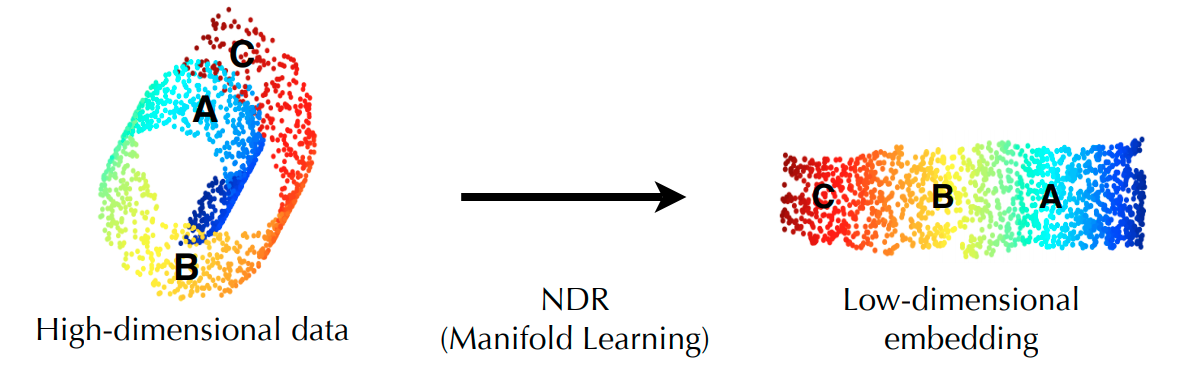

**What is a Manifold?**

**Analogy:**

Imagine you’re an ant walking on a globe. To you, the surface seems flat, but in reality, it’s curved. The globe is a manifold: locally flat, but globally curved. Manifold learning tries to "unroll" this globe into a flat map, preserving the true distances as much as possible.

**Why do we care?**

High-dimensional data (e.g., images, text, or sensor data) often lies on a lower-dimensional "surface" (manifold) embedded in a high-dimensional space.
Manifold learning helps us discover and visualize this hidden structure.

## ISOMAP

---

Isomap stands for **ISOmetric feature MAPping**. Isomap is a non-linear dimensionality reduction method based on the spectral theory which tries to preserve the geodesic distances in the lower dimension.

#### But what are Geodesic Distances?



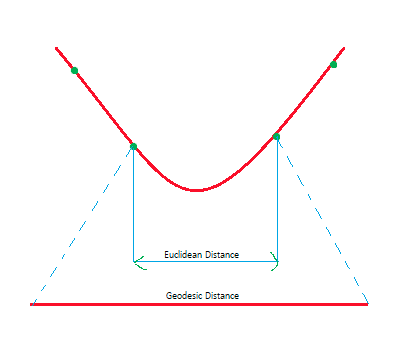

**Euclidean vs. Geodesic Distances:**

- Euclidean distance: Straight-line distance between two points.
- Geodesic distance: Shortest path along the surface of the manifold.

**Example:**

On Earth, the Euclidean distance between two cities is a straight line through the planet (useless!). The geodesic distance is the great-circle distance (what GPS uses).

The next question should be:

*How can we compute geodesics without knowing the manifold?* .......
ANSWER: So we build an adjacency graph and approximate geodesic distances by shortest-paths through the graph.


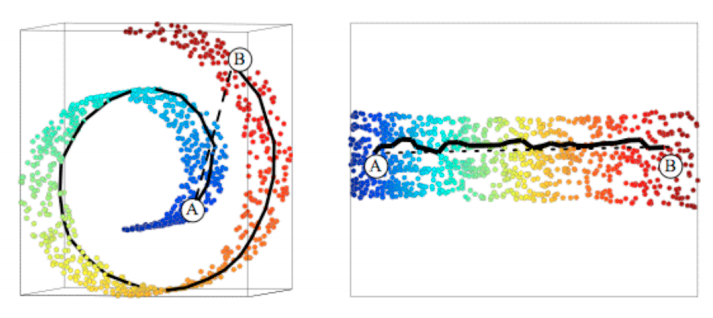

#### 3 steps for ISOMAP:

1. Build the adjacency graph over the points using a Neighbourhood selection method (let's say k nearest neighbours)
2. Compute approximate geodesics: Weight graph edges by inter-point distances and then apply Dijkstra’s all-pairs shortest-paths algorithm.
3. Take the top d eigenvectors of the Gram matrix.


**What is Isomap?**

Isomap is like a GPS for data points. Instead of using straight-line (Euclidean) distances, it uses "road distances" (geodesic distances) to map the data.
It’s useful when data points are connected in a non-linear way (e.g., a curved surface).

**Example:**

Think of a piece of paper rolled into a tube. If you measure distances along the paper (not through the air), you’re using geodesic distances. Isomap tries to "flatten" the tube while keeping these distances accurate.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn import datasets

First let us simulate a dataset with the points lying on a manifold which we would want our Isomap to be able to capture.

We will be using the make_s_curve() function in the sklearn.datasets module to make the manifold using 1000 data points

In [2]:
n_points = 1000
X, color = datasets.make_s_curve(n_points, random_state=0)

**Why use the S-curve?**

The S-curve is a classic example of a 2D manifold embedded in 3D space.
It’s non-linear, so linear methods like PCA struggle to "unroll" it, but Isomap can.

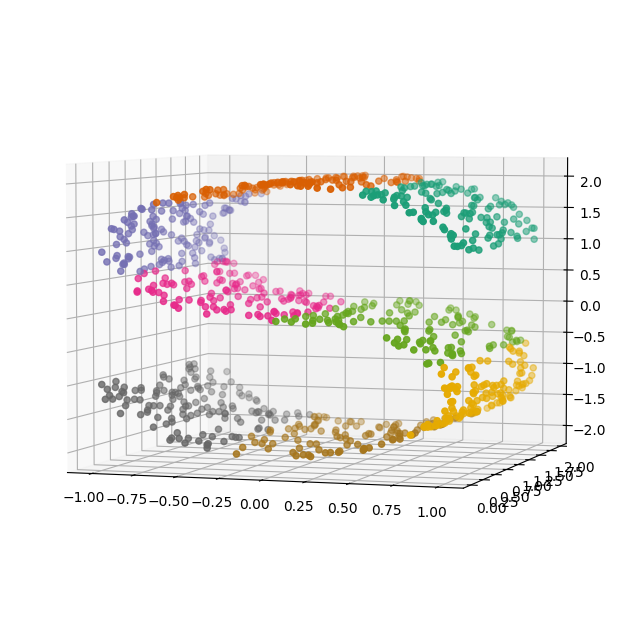

In [3]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=color, cmap=plt.cm.Dark2)
ax.view_init(4, -72)

**Observation:**

- The S-curve is a 2D surface (a sheet of paper) bent in 3D space.
- Isomap will try to "unbend" this surface into a flat 2D plane.

Note that all the points appear to be a lying on a curved 2d plane in this 3d dataset. Now we will be coding the Isomap algorithm to perform this manifold learning.


---

### Step 1a: First lets compute the distance matrix (pairwise Euclidean distances) from the data


In [4]:
def dist(a, b):
  '''Computes Euclidean distance between 2 points'''
  return np.sqrt(sum((a - b) ** 2))

distances = np.array([[dist(p1, p2) for p2 in X] for p1 in X])

# For N points in the dataset, this matrix should be of the dimension NxN.
# Our dataset had 1000 points, so we expect the dimensions of this matrix to be 1000x1000
print(distances.shape)

(1000, 1000)


**What’s happening?**

- We compute the Euclidean distance between every pair of points.
- This gives us an N x N matrix, where N is the number of points (1000 here).

### Step 1b: Let us keep only k nearest neighbors for each point in the distance matrix.

In [5]:
# Lets keep only the 10 nearest neighbors, others set to 0 (= unreachable)

n_neighbors = 10
neighbors = np.zeros(distances.shape)

sort_distances = np.argsort(distances, axis=1)[:, 1:n_neighbors+1]
for k,i in enumerate(sort_distances):
    neighbors[k,i] = distances[k,i]

In [6]:
neighbors.shape

(1000, 1000)

**Adjacency Graph**

**What’s happening?**

- We connect each point to its k nearest neighbors, creating a network (graph).
- This graph approximates the true shape of the manifold.

**Analogy:**

Imagine you’re in a maze. You can only see nearby walls (neighbors). By connecting to your neighbors, you can find the shortest path to any other point in the maze.



---

### Step 2: Weight graph edges by inter-point distances and then apply Dijkstra’s all-pairs shortest-paths algorithm.

We will be using the graph_shortest_path() function in the sklearn.utils.graph module.

The function takes an array of positive distances as the parameter. It then performs a shortest-path graph search on the graph and returns a matrix G (shape = N,N), where, G(i,j) gives the shortest distance from point i to point j along the graph.


In [7]:
from scipy.sparse.csgraph import shortest_path

graph = shortest_path(neighbors, directed=False)

**Dijkstra’s Algorithm**

**What’s happening?**

- We calculate the shortest path between every pair of points using Dijkstra’s algorithm.
- This gives us the "true" distances along the manifold, not just straight-line distances.

**Example:**

If you’re driving from Delhi to Mumbai, the road distance (geodesic) is longer than the straight-line (Euclidean) distance on a map. Isomap uses the road distance.



---
### Step 3: Take the top d eigenvectors of the Gram matrix.


### Step 3: Construct and center the Gram matrix

Classical multidimensional scaling converts the squared geodesic-distance matrix into a centered Gram matrix. It does **not** simply calculate `graph.T @ graph`.

The implementation below first calculates `-0.5 * graph**2`, then double-centers it by subtracting row and column means and adding the overall mean. The leading eigenvectors of this centered matrix provide the low-dimensional coordinates.

In [8]:
# Classical MDS: convert squared geodesic distances into a centered Gram matrix
gram = -0.5 * (graph ** 2)


We will now be computing the eigenvectors for this matrix, so lets first center the data points.

In [9]:
n_samples = gram.shape[0]

# Double-centering: B = -1/2 * J * D^2 * J
meanrows = np.mean(gram, axis=0)
meancols = np.mean(gram, axis=1)[:, np.newaxis]
meanall = np.mean(gram)

gram = gram - meanrows - meancols + meanall


Computing eigenvectors

In [10]:
# The centered Gram matrix is symmetric, so use eigh for stable real eigenvalues/eigenvectors.
eig_val_cov, eig_vec_cov = np.linalg.eigh(gram)

# Sort eigenvalues in descending order and keep the corresponding eigenvectors.
order = np.argsort(eig_val_cov)[::-1]
eig_val_cov = eig_val_cov[order]
eig_vec_cov = eig_vec_cov[:, order]

n_components = 2
# Small negative eigenvalues can occur from numerical error; clip them to zero.
positive_eigenvalues = np.maximum(eig_val_cov[:n_components], 0)
reduced_matrix = eig_vec_cov[:, :n_components] * np.sqrt(positive_eigenvalues)


**Eigenvectors and the Gram Matrix**

**What’s happening?**

- We compute the Gram matrix (a matrix of inner products) and find its top eigenvectors.
- These eigenvectors give us the coordinates in the lower-dimensional space.

**Analogy:**

Think of the Gram matrix as a "distortion detector." The top eigenvectors help us "unfold" the manifold into a flat space.



---

## Plotting the resultant reduced_matrix


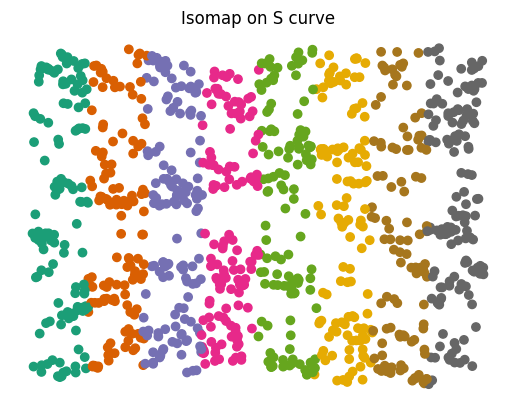

In [11]:
ax = fig.add_subplot(111)
plt.scatter(reduced_matrix[:, 0], reduced_matrix[:, 1], c=color, cmap=plt.cm.Dark2)
plt.title("Isomap on S curve")
plt.axis('off')
plt.show()

**Isomap on the S-Curve**

**What’s happening in the code?**

- We generate a 3D S-shaped curve.
- We compute pairwise distances and keep only the k nearest neighbors.
- We use Dijkstra’s algorithm to find the shortest paths (geodesics).
- We reduce the data to 2D using eigenvectors.

**Visualization:**

The 3D S-curve is "unrolled" into a 2D plane, preserving the structure.

##### As you can see the Isomap was able to capture the underlying 2d manifold in the S curve dataset.

Now of course there is an easier way to do this, using a predefined library Isomap by sklearn in the manifold module. It just requires you to enter the number of neighbours to be considered and the number of components the graph is to be reduced to.


In [12]:
from sklearn.manifold import Isomap

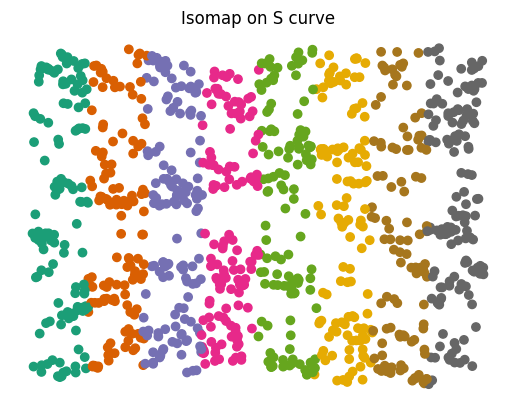

In [13]:
Y = Isomap(n_neighbors=10, n_components=2).fit_transform(X)

ax = fig.add_subplot(111)
plt.scatter(Y[:, 0], Y[:, 1], c=color, cmap=plt.cm.Dark2)
plt.title("Isomap on S curve")
plt.axis('off')
plt.show()

In [14]:
# Numerical checks for the S-curve experiment
print("Input data shape:", X.shape)
print("Pairwise Euclidean distance matrix shape:", distances.shape)
print("Neighborhood matrix shape:", neighbors.shape)
print("Geodesic distance matrix shape:", graph.shape)
print("Manual Isomap embedding shape:", reduced_matrix.shape)
print("Scikit-learn Isomap embedding shape:", Y.shape)
print("All geodesic distances finite:", bool(np.isfinite(graph).all()))
print("All manual embedding coordinates finite:", bool(np.isfinite(reduced_matrix).all()))
print("All scikit-learn embedding coordinates finite:", bool(np.isfinite(Y).all()))
print("Two largest Gram-matrix eigenvalues:", eig_val_cov[:2])

Input data shape: (1000, 3)
Pairwise Euclidean distance matrix shape: (1000, 1000)
Neighborhood matrix shape: (1000, 1000)
Geodesic distance matrix shape: (1000, 1000)
Manual Isomap embedding shape: (1000, 2)
Scikit-learn Isomap embedding shape: (1000, 2)
All geodesic distances finite: True
All manual embedding coordinates finite: True
All scikit-learn embedding coordinates finite: True
Two largest Gram-matrix eigenvalues: [8004.04888132  393.86203926]


**Why Use sklearn?**
**Why use sklearn's Isomap?**

- The manual implementation helps you understand the math, but sklearn is optimized and easier to use.
- It’s also more robust for real-world datasets.



---

### Now let us see if Isomap can learn the manifold representation in some more complex datasets

In [15]:
from sklearn.datasets import fetch_lfw_people

try:
    faces = fetch_lfw_people(min_faces_per_person=200)
    print("LFW dataset loaded. Data shape:", faces.data.shape)
except Exception as exc:
    faces = None
    print("LFW dataset could not be downloaded or loaded.")
    print("This part of the lab requires internet access or a previously cached LFW dataset.")
    print("Details:", type(exc).__name__, str(exc))


LFW dataset loaded. Data shape: (766, 2914)


The original lab notes describe the LFW dataset as 766 images with 2,914 pixel features per image. **This description applies only when the dataset loads successfully.** In this run, the download was unavailable, so the image visualization is skipped. If the dataset loads, the actual shape is printed in the output of the preceding cell and should be used as the verified value.

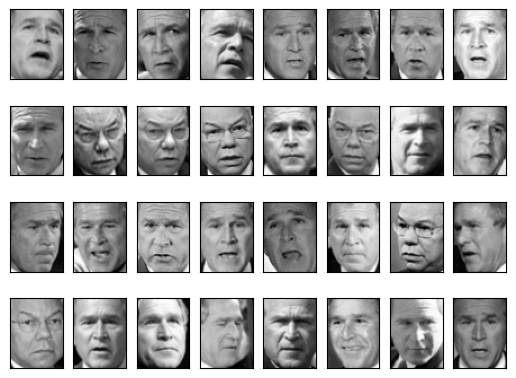

In [16]:
if faces is not None:
    fig, ax = plt.subplots(4, 8, subplot_kw=dict(xticks=[], yticks=[]))
    for i, axi in enumerate(ax.flat):
        axi.imshow(faces.images[i], cmap='gray')
    plt.show()
else:
    print("Skipped face-image visualization because the LFW dataset is unavailable.")


**Why Faces?**

Face images are high-dimensional because each pixel contributes a feature. Variations in pose, lighting, and appearance may lie on a lower-dimensional manifold. Isomap can be used to explore this structure, provided the LFW dataset is successfully loaded.

If the LFW dataset loads, each image is represented by its pixel features. PCA is applied first to examine how much variance is captured by the first 100 components. The cumulative explained-variance plot is generated by the next code cell. If the dataset is unavailable, that code cell reports that the PCA plot was skipped.

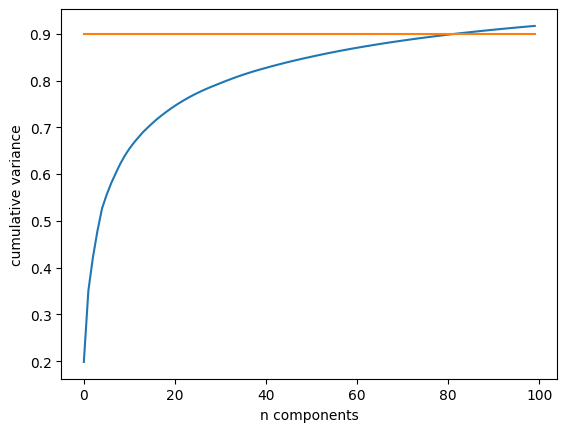

In [17]:
if faces is not None:
    from sklearn.decomposition import PCA
    model = PCA(n_components=100, svd_solver="randomized", random_state=0).fit(faces.data)
    plt.plot(np.cumsum(model.explained_variance_ratio_))
    plt.xlabel('n components')
    plt.ylabel('cumulative variance')
    plt.plot(range(100), 0.9 * np.ones(100))
    plt.show()
else:
    print("Skipped PCA variance plot because the LFW dataset is unavailable.")


If the LFW dataset is available, apply Isomap to reduce the face-image features to two dimensions. The code cell below prints the resulting projection shape. Otherwise, the experiment is skipped and no face projection result is claimed.

In [18]:
if faces is not None:
    model = Isomap(n_components=2, n_neighbors=5)
    proj = model.fit_transform(faces.data)
    print("Isomap projection shape:", proj.shape)
else:
    print("Skipped Isomap face projection because the LFW dataset is unavailable.")


Isomap projection shape: (766, 2)


When the LFW dataset is available, the two-dimensional Isomap projection is visualized with face thumbnails to inspect relationships between images. The plot is generated only when the dataset has loaded successfully.

In [19]:
from matplotlib import offsetbox

def plot_components(data, model, images=None, ax=None, thumb_frac=0.05, cmap='gray'):

    ax = ax or plt.gca()
    proj = model.fit_transform(data)
    ax.plot(proj[:, 0], proj[:, 1], '.k')

    if images is not None:
        min_dist_2 = (thumb_frac * max(proj.max(0) - proj.min(0))) ** 2
        shown_images = np.array([2 * proj.max(0)])
        for i in range(data.shape[0]):
            dist = np.sum((proj[i] - shown_images) ** 2, 1)
            if np.min(dist) < min_dist_2:
                # don't show points that are too close
                continue
            shown_images = np.vstack([shown_images, proj[i]])
            imagebox = offsetbox.AnnotationBbox(
                offsetbox.OffsetImage(images[i], cmap=cmap),
                                      proj[i])
            ax.add_artist(imagebox)

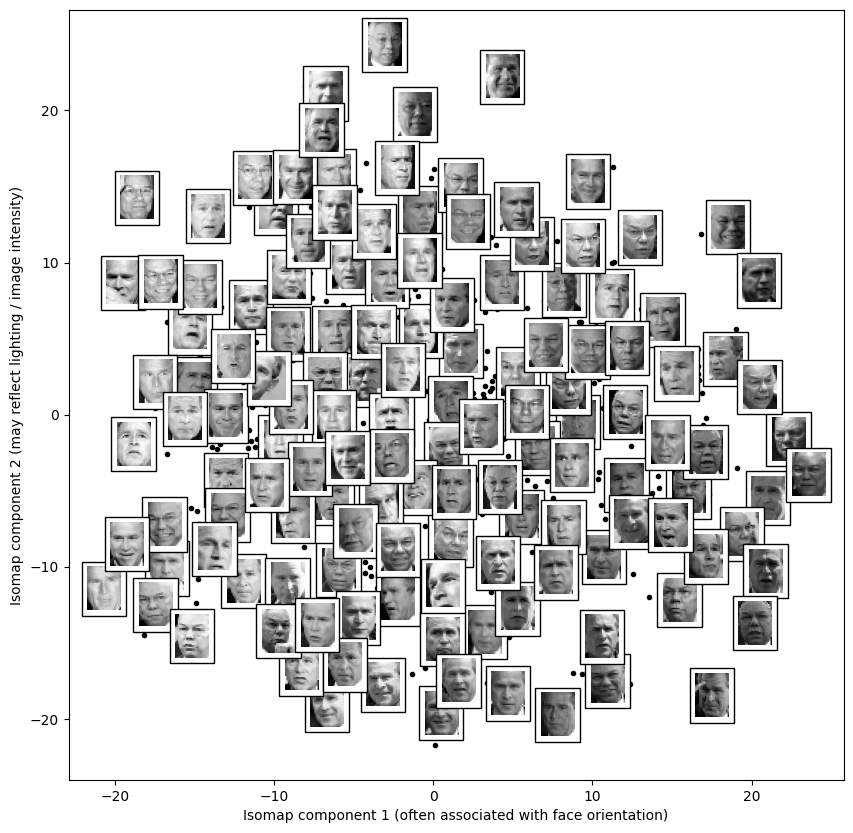

In [20]:
if faces is not None:
    fig, ax = plt.subplots(figsize=(10, 10))
    plot_components(
        faces.data,
        model=Isomap(n_components=2, n_neighbors=5),
        images=faces.images[:, ::2, ::2],
        ax=ax
    )
    plt.xlabel("Isomap component 1 (often associated with face orientation)")
    plt.ylabel("Isomap component 2 (may reflect lighting / image intensity)")
    plt.show()
else:
    print("Skipped face embedding visualization because the LFW dataset is unavailable.")


**PCA vs. Isomap on Faces**

**Observation (when the LFW dataset loads successfully):**
- The cumulative explained-variance plot can be used to see how many PCA components are needed to reach 90% variance. Read the exact component count from the generated plot rather than assuming a fixed value.
- Isomap reduces the high-dimensional face images to two dimensions, allowing their relationships to be visualized.

**Interpreting the Face Plot**
- Inspect the generated embedding for visible groupings or smooth changes in pose, lighting, and appearance.
- The axes are learned coordinates; their meanings are not guaranteed and may vary with the dataset and parameters.


**You are motivated to play around with the number of neighbors and check if the following holds true across neighbourhoods!**

---


# Exercises!!

1. How do you think would the number of neighbors effect the Isomap algorithm? What happens when the number of neighbors considered is very large? What happens when it is very low?

2. When is the ISOMAP algorithm superior to PCA?

3. Search up another manifold learning methods other than ISOMAP? If there are any, whats the key difference ?

4. Suggest ways to deal with missing data in manifold learning.


---

## Answers to Exercises

### 1. How does the number of neighbors affect Isomap? What happens when it is very large or very low?

The number of neighbors, **k**, determines which data points are connected in Isomap's neighborhood graph.

- **Very low k:** The graph may become disconnected or contain too few paths. Geodesic distances can become infinite or inaccurate, so the embedding may be fragmented or distorted.
- **Suitable k:** The graph usually captures local relationships while preserving the overall nonlinear structure.
- **Very high k:** Many distant points become connected directly. These shortcut edges make graph distances resemble Euclidean distances, weakening Isomap's ability to preserve the manifold's curved structure.

**Conclusion:** Select k carefully and compare embeddings across several values.

### 2. When is Isomap superior to PCA?

Isomap is preferable when data lie on a **nonlinear manifold** and meaningful relationships follow paths along that manifold. It estimates **geodesic distances** using a neighborhood graph and shortest paths, then embeds the data in a lower-dimensional space.

PCA is a linear dimensionality-reduction method that preserves directions of maximum variance. It is often faster and more robust, but it may not unfold curved structures such as an S-curve. Therefore, Isomap can be superior for revealing nonlinear structure, provided the neighborhood graph is appropriate and the data are not too noisy.

### 3. Name another manifold-learning method and state its key difference from Isomap.

**Locally Linear Embedding (LLE)** is another nonlinear manifold-learning method.

- **Isomap:** Builds a neighborhood graph, estimates geodesic distances with shortest paths, and uses multidimensional-scaling-style eigen-decomposition to create the embedding.
- **LLE:** Represents each point as a weighted combination of its nearest neighbors, then finds low-dimensional coordinates that preserve those local reconstruction weights.

**Key difference:** Isomap aims to preserve global geodesic distances, whereas LLE focuses on preserving local neighborhood relationships.

### 4. Suggest ways to deal with missing data in manifold learning.

Possible approaches include:

1. **Imputation:** Fill missing numerical values using a suitable method, such as median imputation or K-nearest-neighbor imputation, before constructing the neighborhood graph.
2. **Remove unsuitable samples or features:** Drop rows or columns only when the amount of missing data justifies it and enough representative data remain.
3. **Use a distance function that supports missing values:** Calculate distances using the observed features and apply appropriate scaling; ensure the resulting distances are comparable.
4. **Validate the embedding:** Compare neighborhood connectivity and embeddings under different reasonable imputation choices.
5. **Prevent data leakage:** Fit imputation only on training data when the embedding is part of a predictive workflow.

**Conclusion:** Missing values should be handled before graph construction because inaccurate distances can create incorrect edges and distort the manifold.


**Challenges of Manifold Learning**

**Key Issues:**

- Noisy data can create "shortcuts" and distort the manifold.
- Choosing k (number of neighbors) is tricky. Too small → fragmented manifold; too large → loses local structure.
- Missing data is harder to handle than in PCA.

**Analogy:**

- If your GPS has bad signal (noisy data), it might suggest a wrong route.
- If you only ask 2 people for directions (k=2), you might miss the best path.
- If you ask 100 (k=100), you’ll get confused!

### Reproducibility note

The S-curve experiment is generated locally and can run without downloading a dataset. The later face-image experiment uses `fetch_lfw_people`, which may require internet access on the first run. If the dataset is unavailable, the notebook now reports this clearly and skips only the face-specific cells; rerun those cells when internet access or a cached LFW dataset is available.


## Experiment Observation and Result

### Observations
- The generated S-curve has **1,000 samples** and **3 input features**, as represented by the shape `(1000, 3)`.
- The pairwise distance matrix and the neighborhood matrix each have shape `(1000, 1000)`.
- With `n_neighbors = 10`, the graph is used to estimate manifold distances through shortest paths.
- The manual Isomap and scikit-learn Isomap sections produce two-dimensional embeddings with shape `(1000, 2)`. The plotted coordinates can differ by rotation, reflection, translation, or scale while representing a similar structure.
- The verification cell confirmed that the input data, distance matrices, graph, and both S-curve embeddings have the expected shapes and finite values. The LFW face-data download was attempted, but in this execution environment it failed because internet access was unavailable. Therefore, the face images, PCA variance curve, and face Isomap projection are **not claimed as observed results**. The notebook skips those steps with an explanatory message.

### Result
Isomap was implemented on the synthetic S-curve by constructing a neighborhood graph, calculating graph shortest-path distances, and applying classical MDS. The dataset was reduced from three dimensions to two dimensions. The scikit-learn implementation was also run for comparison. The face-image extension remains conditional on obtaining the LFW dataset.



## Conclusion:
In practice manifold learning techniques tend to be finicky enough that they are rarely used for anything more than simple qualitative visualization of high-dimensional data.

The following are some of the particular challenges of manifold learning, which all contrast poorly with PCA:

1) In manifold learning, there is no good framework for handling missing data. In contrast, there are straightforward iterative approaches for missing data in PCA.

2) In manifold learning, the presence of noise in the data can "short-circuit" the manifold and drastically change the embedding. In contrast, PCA naturally filters noise from the most important components.

3) The manifold embedding result is generally highly dependent on the number of neighbors chosen, and there is generally no solid quantitative way to choose an optimal number of neighbors. In contrast, PCA does not involve such a choice.

4) In manifold learning, the globally optimal number of output dimensions is difficult to determine. In contrast, PCA lets you find the output dimension based on the explained variance.

5) In manifold learning, the meaning of the embedded dimensions is not always clear. In PCA, the principal components have a very clear meaning.

6) In manifold learning the computational expense of manifold methods scales as O[N^2] or O[N^3]. For PCA, there exist randomized approaches that are generally much faster (though see the megaman package for some more scalable implementations of manifold learning).

Therefore with all that on the table, the only clear advantage of manifold learning methods over PCA is their ability to preserve nonlinear relationships in the data; for that reason I tend to explore data with manifold methods only after first exploring them with PCA.



**When to Use Manifold Learning?**

**Use cases:**

- Visualizing high-dimensional data (e.g., genomics, images).
- Preprocessing for clustering or classification.

**Limitations:**

- Not scalable to millions of points.
- Mostly used for exploration, not production.



| Feature               | PCA                          | Isomap                      |
|-----------------------|------------------------------|-----------------------------|
| **Assumption**        | Linear structure             | Non-linear manifold         |
| **Distance Used**     | Euclidean                    | Geodesic                    |
| **Speed**             | Fast                         | Slow (O[N²] or O[N³])        |
| **Handles Noise?**    | Yes                          | Sensitive to noise          |
| **Missing Data?**     | Easy (iterative imputation)  | Hard                        |
| **Output Dimensions** | Clear (explained variance)   | Ambiguous                   |
| **Scalability**       | High (randomized methods)    | Low (computationally heavy) |
| **Use Case**          | General-purpose              | Non-linear visualization    |



---


### Some interesting references:

1) https://axon.cs.byu.edu/Dan/678/miscellaneous/Manifold.example.pdf

2) http://vision.cse.psu.edu/seminars/talks/PRML/David_NDR_lecture.pdf


---

